[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josterri/predicting-the-next-words-notebooks/blob/main/ch09-simple_workbook.ipynb)

# Hidden words in Pride and Prejudice

BERT hides 15 per cent of a text's words and predicts each from both sides;
GPT predicts every next word from the words before it. On a chapter of the
novel, how many loss terms does each give, and how often does a guess from
both sides beat a guess from the word before? How many bits does the
novel's opening cost, and what do T5's encoder input and target look like?

In [1]:
#@title Setup: run this cell first
import os
import re
import urllib.request
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

MIRROR_REF = "main"
TEXT_URL = f"https://raw.githubusercontent.com/josterri/predicting-the-next-words-notebooks/{MIRROR_REF}/data/pride_and_prejudice.txt"


def load_novel():
    """Pride and Prejudice as lowercase word tokens, one list per chapter."""
    if os.environ.get("PNW_TEXT"):
        text = open(os.environ["PNW_TEXT"], encoding="utf-8").read()
    else:
        try:
            text = urllib.request.urlopen(TEXT_URL).read().decode("utf-8")
        except OSError as e:
            raise RuntimeError(f"The text did not download from {TEXT_URL}: {e}. "
                               "Run this cell again; every cell below needs it.") from None
    chapters = re.split(r"(?m)^CHAPTER [IVXLC]+\.$", text)[1:]
    return [re.findall(r"[a-z]+(?:'[a-z]+)*", c.lower().replace("’", "'")) for c in chapters]


# BERT selects 15 per cent of positions (Devlin et al. 2019); T5 hides spans of 3 on average (Raffel et al. 2020).
PER_CENT, SPAN = 15, 3
plt.rcParams.update({"xtick.labelsize": 8, "ytick.labelsize": 8})


class Refused(Exception):  # a setting a cell refuses: Colab prints the one sentence, without the stack
    _render_traceback_ = lambda self: [str(self)]  # noqa: E731


chapters = load_novel()
unigrams = Counter(w for c in chapters for w in c)
bigrams = Counter(p for c in chapters for p in zip(c, c[1:]))
by_chapter = [Counter(zip(c, c[1:])) for c in chapters]
following = defaultdict(list)  # the words seen after each word, in the order the novel first shows them
for a, b in bigrams:
    following[a].append(b)


def chapter(k):  # a chapter number typed in a cell
    if type(k) is not int or not 1 <= k <= len(chapters):
        raise Refused(f"CHAPTER is {k!r}: CHAPTER takes a whole number from 1 to {len(chapters)}.")
    return chapters[k - 1]


def held_out(k):  # pair and word counts of the novel without chapter k, so no guess has seen its answer
    pairs, words = by_chapter[k - 1], Counter(chapters[k - 1])
    return (lambda a, b: bigrams[(a, b)] - pairs[(a, b)]), (lambda w: unigrams[w] - words[w])


def bars(title, labels, values, xlabel, colors, fmt="%.1f"):  # one chart of labelled horizontal bars
    fig, ax = plt.subplots(figsize=(6, 0.3 * len(values) + 1.2), layout="constrained")
    b = ax.barh(range(len(values)), values, tick_label=labels, color=colors)
    ax.bar_label(b, fmt=fmt, padding=2, fontsize=8)
    ax.set(title=title, xlabel=xlabel, xlim=(0, 1.25 * (max(values) or 1)), ylim=(len(values) - 0.5, -0.5))
    plt.show()


# Step 1: the loss terms of one causal pass and one masked pass over a chapter.
def loss_terms(k, rate):
    T = len(chapter(k))
    if type(rate) not in (int, float) or not 0 < rate <= 1:
        raise Refused(f"MASK_RATE is {rate!r}: MASK_RATE takes a number above 0 and up to 1.")
    print(f"chapter {k}: {T:,} words; causal pass {T:,} loss terms, masked pass {rate * T:,.1f}; ratio {1 / rate:.2f}")
    bars(f"chapter {k}, mask rate {rate:g}", ["causal pass", "masked pass"], [T, rate * T], "loss terms", ["C0", "C3"])


# Step 2: every EVERY-th word hidden and guessed from the word before, then from both neighbours.
def guesses(k, every):
    words, (pair, count) = chapter(k), held_out(k)
    if type(every) is not int or not 3 <= every <= 50:
        raise Refused(f"EVERY is {every!r}: EVERY takes a whole number from 3 to 50.")
    rows = []
    for i in range(every - 1, len(words) - 1, every):
        prev, nxt = words[i - 1], words[i + 1]
        seen = [w for w in following[prev] if pair(prev, w) > 0]
        left = max(seen, key=lambda w: pair(prev, w), default="")
        both = max(seen, key=lambda w: pair(prev, w) * pair(w, nxt) / count(w), default="")
        rows.append((words[i], left, both if both and pair(both, nxt) > 0 else left))
    return rows


def right(rows):  # per cent of hidden words guessed right from the word before, and from both neighbours
    return [100 * float(np.mean([r[0] == r[j] for r in rows])) for j in (1, 2)]


def compare(k, every):
    rows = guesses(k, every)
    print(f"chapter {k}: {len(rows)} hidden words; first five, hidden: before / both: "
          + "; ".join(f"{h}: {a} / {b}" for h, a, b in rows[:5]))
    bars(f"chapter {k}, every {every}th word hidden", ["the word before (causal)", "both neighbours (masked)"],
         right(rows), "per cent guessed right", ["C0", "C3"])


# Step 3: bits of the first n words under word-pair counts of the other chapters, one added to each count.
def bits_of(k, n):
    words, (pair, count) = chapter(k), held_out(k)
    if type(n) is not int or not 2 <= n <= len(words):
        raise Refused(f"N is {n!r}: N takes a whole number from 2 to {len(words)}.")
    return words[:n], [float(-np.log2((pair(a, b) + 1) / (count(a) + len(unigrams)))) for a, b in zip(words, words[1:n])]


def opening(k, n):
    if type(n) is not int or not 2 <= n <= 40:
        raise Refused(f"N is {n!r}: N takes a whole number from 2 to 40.")
    words, bits = bits_of(k, n)
    print(f"{n - 1} predictions: {sum(bits):.2f} bits, {np.mean(bits):.2f} bits per word, perplexity {2 ** np.mean(bits):.1f}")
    bars(f"chapter {k}, first {n} words", [f"{b} after {a}" for a, b in zip(words, words[1:])], bits, "bits",
         ["C3" if x == max(bits) else "C0" for x in bits])


# Appendix: T5's span corruption, K hidden words in S evenly spaced spans of about SPAN words.
def sentinel(j):
    return "<" + "XYZ"[j] + ">" if j < 3 else f"<S{j + 1}>"


def corrupt(words):
    T = len(words)
    K = round(PER_CENT / 100 * T)
    S = max(1, round(K / SPAN))
    sizes = [K // S + (j < K % S) for j in range(S)]
    inp, tgt, last = [], [], 0
    for j, m in enumerate(sizes):
        a = int((j + 0.5) * T / S) - m // 2
        inp, tgt, last = inp + words[last:a] + [sentinel(j)], tgt + [sentinel(j)] + words[a:a + m], a + m
    return inp + words[last:], tgt + [sentinel(S)], K, S


display(Markdown(f"The novel: {len(chapters)} chapters, {sum(unigrams.values()):,} words, {len(unigrams):,} different "
                 f"words and {len(bigrams):,} different pairs of neighbouring words."))

The novel: 61 chapters, 122,174 words, 6,314 different words and 54,324 different pairs of neighbouring words.

## 1. Loss terms per pass

A causal pass over a chapter predicts every word from the words before it,
one loss term per word. A masked pass selects a share `MASK_RATE` of the
positions and takes a loss term at those alone. Run the cell for chapter 1
at BERT's 0.15: how many loss terms does each pass give? Then set
`MASK_RATE` to 0.25 and `CHAPTER` to another chapter.

chapter 1: 853 words; causal pass 853 loss terms, masked pass 127.9; ratio 6.67


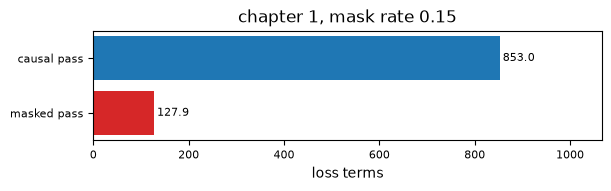

In [2]:
CHAPTER = 1
MASK_RATE = 0.15
loss_terms(CHAPTER, MASK_RATE)

### Solution

In [3]:
total = sum(unigrams.values())
display(Markdown(f"Chapter 1 has {len(chapters[0]):,} words: {len(chapters[0]):,} causal loss terms against "
                 f"{0.15 * len(chapters[0]):,.1f} masked ones, {1 / 0.15:.2f} times as many, and {1 / 0.25:.0f} times at 0.25. "
                 f"The ratio holds for every chapter: over the whole novel {total:,} against {0.15 * total:,.0f}."))

Chapter 1 has 853 words: 853 causal loss terms against 127.9 masked ones, 6.67 times as many, and 4 times at 0.25. The ratio holds for every chapter: over the whole novel 122,174 against 18,326.

## 2. One side or both sides

The cell hides every `EVERY`-th word of the chapter and guesses each from
the counts of the other chapters. The causal guess is the word that most
often follows the word before. The masked guess also reads the word after:
a candidate scores how often it follows the word before, times how often the
word after follows it, divided by how often it occurs. Run the cell with
every 7th word hidden: which guess is right more often? Then set `EVERY` to 3.

chapter 1: 121 hidden words; first five, hidden: before / both: that: to / with; a: the / the; of: of / of; feelings: whole / two; may: who / to


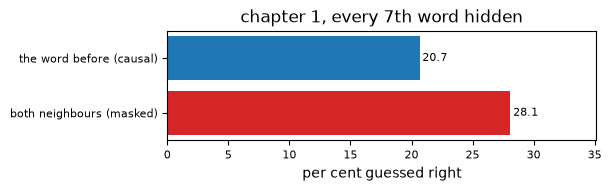

In [4]:
CHAPTER = 1
EVERY = 7
compare(CHAPTER, EVERY)

### Solution

In [5]:
r7, r3, novel = right(guesses(1, 7)), right(guesses(1, 3)), right([r for k in range(1, len(chapters) + 1) for r in guesses(k, 7)])
display(Markdown(f"Chapter 1, every 7th word: {r7[0]:.1f} per cent right from the word before, {r7[1]:.1f} from both "
                 f"neighbours; every 3rd word: {r3[0]:.1f} and {r3[1]:.1f}. Over all {len(chapters)} chapters "
                 f"{novel[0]:.1f} against {novel[1]:.1f}: the word after rules out candidates the word before allows."))

Chapter 1, every 7th word: 20.7 per cent right from the word before, 28.1 from both neighbours; every 3rd word: 14.1 and 27.8. Over all 61 chapters 12.8 against 20.8: the word after rules out candidates the word before allows.

## 3. Bits and perplexity of the opening

A causal model of word pairs, counted over the other chapters with one added
to every count, gives each word of a chapter a probability from the word
before it. The cell adds the bits of the first `N` words, the first one input
only, and turns the bits per word into a perplexity, 2 to the bits per word.
Run the cell for the novel's first 12 words: which word costs most? Then set
`N` to 40.

11 predictions: 113.97 bits, 10.36 bits per word, perplexity 1315.4


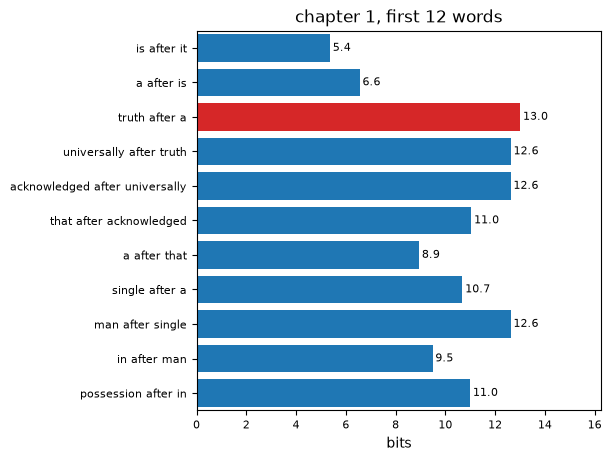

In [6]:
CHAPTER = 1
N = 12
opening(CHAPTER, N)

### Solution

In [7]:
(w12, b12), (w1, b1) = bits_of(1, 12), bits_of(1, len(chapters[0]))
top = int(np.argmax(b12))
display(Markdown(f"The first 12 words cost {sum(b12):.2f} bits, {np.mean(b12):.2f} per word, a perplexity of {2 ** np.mean(b12):.1f}; "
                 f"`{w12[top + 1]}` after `{w12[top]}` costs most, {b12[top]:.2f} bits. Over all of chapter 1 the "
                 f"perplexity is {2 ** np.mean(b1):.1f}, from {len(b1):,} predictions."))

The first 12 words cost 113.97 bits, 10.36 per word, a perplexity of 1315.4; `truth` after `a` costs most, 13.01 bits. Over all of chapter 1 the perplexity is 1144.6, from 852 predictions.

## Appendix. Span corruption of the opening

T5 hides 15 per cent of a text in spans of 3 words on average. Each span
becomes one sentinel token in the encoder input, and the target writes each
span after its sentinel and ends on one more sentinel. With K of T words
hidden in S spans the encoder reads T − K + S tokens and the decoder predicts
K + S + 1. The cell corrupts the first 40 words of chapter 1.

input:  it is a truth universally acknowledged that a single <X> of a good fortune must be in want of a wife however little known the feelings or <Y> a man may be on his first entering
target: <X> man in possession <Y> views of such <Z>
K = 6 hidden words in S = 2 spans: 36 encoder inputs, 9 targets


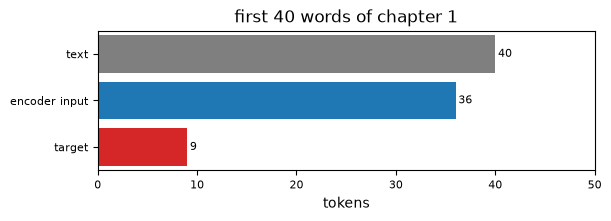

In [8]:
inp, tgt, K, S = corrupt(chapters[0][:40])
print("input:  " + " ".join(inp) + "\ntarget: " + " ".join(tgt))
print(f"K = {K} hidden words in S = {S} spans: {len(inp)} encoder inputs, {len(tgt)} targets")
bars("first 40 words of chapter 1", ["text", "encoder input", "target"], [40, len(inp), len(tgt)], "tokens",
     ["C7", "C0", "C3"], "%d")

**Exercise.** Set `LENGTH` to 512, the length BERT and T5 train on. How many
encoder inputs and targets do the first 512 words of chapter 1 give, and how
far are they from T − K + S and K + S + 1 with K and S left unrounded?

In [9]:
LENGTH = 40

if type(LENGTH) is not int or not 10 <= LENGTH <= len(chapters[0]):
    raise Refused(f"LENGTH is {LENGTH!r}: LENGTH takes a whole number from 10 to {len(chapters[0])}.")
inp, tgt, K, S = corrupt(chapters[0][:LENGTH])
print(f"{LENGTH} words: K = {K}, S = {S}; {len(inp)} encoder inputs and {len(tgt)} targets")

40 words: K = 6, S = 2; 36 encoder inputs and 9 targets


### Solution

In [10]:
inp, tgt, K, S = corrupt(chapters[0][:512])
k, s = PER_CENT / 100 * 512, PER_CENT / 100 * 512 / SPAN
display(Markdown(f"At 512 words K = {K} and S = {S}: {len(inp)} encoder inputs and {len(tgt)} targets. Unrounded, K = {k:.1f} "
                 f"and S = {s:.1f} give {512 - k + s:.1f} and {k + s + 1:.1f}; whole words and whole spans move each by under 1."))

At 512 words K = 77 and S = 26: 461 encoder inputs and 104 targets. Unrounded, K = 76.8 and S = 25.6 give 460.8 and 103.4; whole words and whole spans move each by under 1.